In [ ]:
import zipfile
import shutil
from pathlib import Path

zip_path = Path(FRAME_ZIP)
extract_root = Path("/content/_tmp_extract")
data_root = Path("/content/data")
frame_root = data_root / FRAME_NAME

if extract_root.exists():
    shutil.rmtree(extract_root)
extract_root.mkdir(parents=True, exist_ok=True)

data_root.mkdir(parents=True, exist_ok=True)
if frame_root.exists():
    shutil.rmtree(frame_root)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_root)

print("Top-level extracted contents:")
for p in sorted(extract_root.iterdir()):
    print(" -", p)

candidates = [p for p in extract_root.rglob(FRAME_NAME) if p.is_dir()]
if not candidates:
    raise FileNotFoundError(f"Could not find folder named {FRAME_NAME} inside {FRAME_ZIP}")

src_frame = candidates[0]
print("Found frame folder at:", src_frame)

shutil.move(str(src_frame), str(frame_root))

print("\nFinal dataset root:", frame_root)
print("Contents:")
for p in sorted(frame_root.iterdir()):
    print(" -", p)

Top-level extracted contents:
 - /content/_tmp_extract/__MACOSX
 - /content/_tmp_extract/images80
Found frame folder at: /content/_tmp_extract/images80/frame_1180

Final dataset root: /content/data/frame_1180
Contents:
 - /content/data/frame_1180/.DS_Store
 - /content/data/frame_1180/colmap.txt
 - /content/data/frame_1180/images
 - /content/data/frame_1180/masks_binary
 - /content/data/frame_1180/sparse


In [ ]:
# =========================
# CONFIG
# =========================

FRAME_NAME = "frame_1180"
FRAME_ZIP = "/content/images80.zip"

RESOLUTION = 4
ITERATIONS = 15000
TEST_COUNT = 5
LAMBDA_MASK = 0.01   # stable silhouette weight

# Choose experiment:
# "normal"      -> masked RGB only (plant-only)
# "alpha"       -> masked RGB only (same practical behavior here)
# "silhouette"  -> masked RGB + silhouette
EXPERIMENT_MODE = "silhouette"

# Output run name
EXP_NAME = f"{FRAME_NAME}_{EXPERIMENT_MODE}_gt"

print("Config loaded")
print("FRAME_NAME      =", FRAME_NAME)
print("EXPERIMENT_MODE =", EXPERIMENT_MODE)
print("EXP_NAME        =", EXP_NAME)

Config loaded
FRAME_NAME      = frame_1180
EXPERIMENT_MODE = silhouette
EXP_NAME        = frame_1180_silhouette_gt


In [ ]:
from pathlib import Path
import shutil

frame_root = Path("/content/data/frame_1180")

# normalize sparse/0
sparse_root = frame_root / "sparse"
if not sparse_root.exists():
    raise FileNotFoundError("No sparse directory found")

if not (sparse_root / "0").exists():
    zero_dir = sparse_root / "0"
    zero_dir.mkdir(exist_ok=True)
    for p in list(sparse_root.iterdir()):
        if p.name == "0":
            continue
        shutil.move(str(p), str(zero_dir / p.name))
    print("✅ Created sparse/0 and moved files into it")
else:
    print("✅ sparse/0 already exists")

# preserve GT masks
gt_src = frame_root / "masks_binary"
gt_dst = frame_root / "masks_binary_gt"
if gt_src.exists() and not gt_dst.exists():
    shutil.move(str(gt_src), str(gt_dst))
    print("✅ Moved masks_binary -> masks_binary_gt")
elif gt_dst.exists():
    print("✅ masks_binary_gt already exists")
else:
    raise FileNotFoundError("No masks_binary found in the dataset zip")

print("\nFinal sparse tree:")
for p in sorted((frame_root / "sparse").rglob("*")):
    print(" -", p.relative_to(frame_root))

✅ sparse/0 already exists
✅ Moved masks_binary -> masks_binary_gt

Final sparse tree:
 - sparse/.DS_Store
 - sparse/0
 - sparse/0/cameras.bin
 - sparse/0/cameras.txt
 - sparse/0/images.bin
 - sparse/0/images.txt
 - sparse/0/points3D.bin
 - sparse/0/points3D.txt


In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import shutil
import os

frame_root = Path("/content/data/frame_1180")
images_dir = frame_root / "images"

# create all-ones masks
ones_dst = frame_root / "masks_binary_ones"
if ones_dst.exists():
    shutil.rmtree(ones_dst)
ones_dst.mkdir(parents=True, exist_ok=True)

for img_path in sorted(images_dir.iterdir()):
    if img_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
        continue
    img = Image.open(img_path)
    ones = np.ones((img.size[1], img.size[0]), dtype=np.uint8) * 255
    Image.fromarray(ones).save(ones_dst / f"{img_path.stem}_mask_ground_truth.png")

# activate GT masks by default
active = frame_root / "masks_binary_active"
if active.exists() or active.is_symlink():
    active.unlink() if active.is_symlink() else shutil.rmtree(active)

os.symlink(frame_root / "masks_binary_gt", active, target_is_directory=True)

print("✅ masks_binary_ones created")
print("✅ masks_binary_active -> masks_binary_gt")

/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))


✅ masks_binary_ones created
✅ masks_binary_active -> masks_binary_gt


In [ ]:
%%bash
set -e

rm -rf /content/Wheat-3DGS

git clone https://github.com/zdwww/Wheat-3DGS.git /content/Wheat-3DGS
cd /content/Wheat-3DGS

git submodule sync --recursive
git submodule update --init --recursive

echo "=== simple-knn ==="
ls -la submodules/simple-knn

echo "=== diff-gaussian-rasterization ==="
ls -la submodules/diff-gaussian-rasterization

echo "=== flashsplat-rasterization ==="
ls -la submodules/flashsplat-rasterization

Submodule path 'submodules/diff-gaussian-rasterization': checked out '8829d14f814fccdaf840b7b0f3021a616583c0a1'
Submodule path 'submodules/diff-gaussian-rasterization/third_party/glm': checked out '5c46b9c07008ae65cb81ab79cd677ecc1934b903'
Submodule path 'submodules/flashsplat-rasterization': checked out 'b7698d2733fcecef2f2e46febdbf8e93735d2a00'
Submodule path 'submodules/simple-knn': checked out '86710c2d4b46680c02301765dd79e465819c8f19'
=== simple-knn ===
total 52
drwxr-xr-x 3 root root 4096 Apr  1 10:55 .
drwxr-xr-x 5 root root 4096 Apr  1 10:55 ..
-rw-r--r-- 1 root root  427 Apr  1 10:55 ext.cpp
-rw-r--r-- 1 root root   49 Apr  1 10:55 .git
-rw-r--r-- 1 root root 4662 Apr  1 10:55 LICENSE.md
-rw-r--r-- 1 root root  830 Apr  1 10:55 setup.py
drwxr-xr-x 2 root root 4096 Apr  1 10:55 simple_knn
-rw-r--r-- 1 root root 6370 Apr  1 10:55 simple_knn.cu
-rw-r--r-- 1 root root  451 Apr  1 10:55 simple_knn.h
-rw-r--r-- 1 root root  671 Apr  1 10:55 spatial.cu
-rw-r--r-- 1 root root  380 Apr

Cloning into '/content/Wheat-3DGS'...
Submodule 'submodules/diff-gaussian-rasterization' (https://github.com/ashawkey/diff-gaussian-rasterization.git) registered for path 'submodules/diff-gaussian-rasterization'
Submodule 'submodules/flashsplat-rasterization' (https://github.com/florinshen/flashsplat-rasterization.git) registered for path 'submodules/flashsplat-rasterization'
Submodule 'submodules/simple-knn' (https://gitlab.inria.fr/bkerbl/simple-knn.git) registered for path 'submodules/simple-knn'
Cloning into '/content/Wheat-3DGS/submodules/diff-gaussian-rasterization'...
Cloning into '/content/Wheat-3DGS/submodules/flashsplat-rasterization'...
Cloning into '/content/Wheat-3DGS/submodules/simple-knn'...
Submodule 'third_party/glm' (https://github.com/g-truc/glm.git) registered for path 'submodules/diff-gaussian-rasterization/third_party/glm'
Cloning into '/content/Wheat-3DGS/submodules/diff-gaussian-rasterization/third_party/glm'...


In [ ]:
%%bash
set -e

export CUDA_HOME=/usr/local/cuda
export CUDACXX=/usr/local/cuda/bin/nvcc
export PATH=/usr/local/cuda/bin:$PATH
export LD_LIBRARY_PATH=/usr/local/cuda/lib64:$LD_LIBRARY_PATH

python -m pip install -q --upgrade pip
pip install -q plyfile ffmpeg-python lpips ninja cmake open3d

TORCH_LIB=$(python -c "import os, torch; print(os.path.join(os.path.dirname(torch.__file__), 'lib'))")
export LD_LIBRARY_PATH=$TORCH_LIB:$LD_LIBRARY_PATH

cd /content/Wheat-3DGS

CUDA_HOME=/usr/local/cuda CUDACXX=/usr/local/cuda/bin/nvcc \
pip install -v --no-build-isolation -e submodules/simple-knn

CUDA_HOME=/usr/local/cuda CUDACXX=/usr/local/cuda/bin/nvcc \
pip install -v --no-build-isolation -e submodules/diff-gaussian-rasterization

CUDA_HOME=/usr/local/cuda CUDACXX=/usr/local/cuda/bin/nvcc \
pip install -v --no-build-isolation -e submodules/flashsplat-rasterization

echo "✅ Extensions built"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 36.1 MB/s eta 0:00:00
Using pip 26.0.1 from /usr/local/lib/python3.12/dist-packages/pip (python 3.12)
Obtaining file:///content/Wheat-3DGS/submodules/simple-knn
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for simple_knn (pyproject.toml): started
  Building editable for simple_knn (pyproject.toml): finished with status 'done'
  Created wheel for simple_knn: filename=simple_knn-0.0.0-0.editable-cp312-cp312-linux_x86_64.whl size=5047 sha256=98c471d334660d707bc7905d8dddde8e1f63ff968f8bca5ffb93fb993a2f8248
  Stored in directory: /tmp/pip-ephem-wheel-cache-uwei49pi/wheels/0f/66/53/21a7d1d0c0717f99b8cc4c3a2ac9beb5affef4f88bac5e4893
Successfully built simple_knn
Using pip 26.0.1 from /usr/local

  Running command Checking if build backend supports build_editable
  Running command Preparing editable metadata (pyproject.toml)
  running dist_info
  creating /tmp/pip-modern-metadata-sh1ylusv/simple_knn.egg-info
  writing /tmp/pip-modern-metadata-sh1ylusv/simple_knn.egg-info/PKG-INFO
  writing dependency_links to /tmp/pip-modern-metadata-sh1ylusv/simple_knn.egg-info/dependency_links.txt
  writing top-level names to /tmp/pip-modern-metadata-sh1ylusv/simple_knn.egg-info/top_level.txt
  writing manifest file '/tmp/pip-modern-metadata-sh1ylusv/simple_knn.egg-info/SOURCES.txt'
  reading manifest file '/tmp/pip-modern-metadata-sh1ylusv/simple_knn.egg-info/SOURCES.txt'
  adding license file 'LICENSE.md'
  writing manifest file '/tmp/pip-modern-metadata-sh1ylusv/simple_knn.egg-info/SOURCES.txt'
  creating '/tmp/pip-modern-metadata-sh1ylusv/simple_knn-0.0.0.dist-info'
  Running command Building editable for simple_knn (pyproject.toml)
  running editable_wheel
  creating /tmp/pip-ephem-wheel

In [ ]:
import os, sys, torch
print(torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("device count:", torch.cuda.device_count())
if torch.cuda.is_available():
    print("gpu name:", torch.cuda.get_device_name(0))

sys.path.insert(0, "/content/Wheat-3DGS")
sys.path.insert(0, "/content/Wheat-3DGS/submodules/simple-knn")
sys.path.insert(0, "/content/Wheat-3DGS/submodules/diff-gaussian-rasterization")
sys.path.insert(0, "/content/Wheat-3DGS/submodules/flashsplat-rasterization")

import simple_knn
print("✅ simple_knn")

import diff_gaussian_rasterization
print("✅ diff_gaussian_rasterization")

import flashsplat_rasterization
print("✅ flashsplat_rasterization")

2.10.0+cu128
cuda available: True
device count: 1
gpu name: Tesla T4
✅ simple_knn
✅ diff_gaussian_rasterization
✅ flashsplat_rasterization


In [ ]:
from pathlib import Path

# -------------------------
# 1) Patch split in dataset_readers.py
# -------------------------
path = Path("/content/Wheat-3DGS/scene/dataset_readers.py")
with open(path, "r") as f:
    lines = f.readlines()

start = None
end = None
for i, line in enumerate(lines):
    if "if eval:" in line and start is None:
        start = i
    if start is not None and "nerf_normalization = getNerfppNorm(train_cam_infos)" in line:
        end = i
        break

assert start is not None and end is not None

new_block = [
    "    if eval:\n",
    f"        test_count = {TEST_COUNT}\n",
    "        train_cam_infos = cam_infos[:-test_count]\n",
    "        test_cam_infos = cam_infos[-test_count:]\n",
    "        print(f\"Train Cam list with {len(train_cam_infos)} cams: {[cam.image_name for cam in train_cam_infos]}\")\n",
    "        print(f\"Test Cam list with {len(test_cam_infos)} cams: {[cam.image_name for cam in test_cam_infos]}\")\n",
    "    else:\n",
    "        train_cam_infos = cam_infos\n",
    "        test_cam_infos = []\n",
]
lines = lines[:start] + new_block + lines[end:]
path.write_text("".join(lines))

# -------------------------
# 2) Add alpha_mask_path and use masks_binary_active
# -------------------------
path = Path("/content/Wheat-3DGS/scene/dataset_readers.py")
text = path.read_text()

if "alpha_mask_path: str" not in text:
    text = text.replace(
        """class CameraInfo(NamedTuple):
    uid: int
    R: np.array
    T: np.array
    FovY: np.array
    FovX: np.array
    image: np.array
    image_path: str
    image_name: str
    width: int
    height: int
    bbox_path: str
    mask_paths: List[str]
""",
        """class CameraInfo(NamedTuple):
    uid: int
    R: np.array
    T: np.array
    FovY: np.array
    FovX: np.array
    image: np.array
    image_path: str
    image_name: str
    width: int
    height: int
    bbox_path: str
    mask_paths: List[str]
    alpha_mask_path: str
"""
    )

if 'masks_binary_active' not in text:
    text = text.replace(
        """        image_path = os.path.join(images_folder, os.path.basename(extr.name))
        image_name = os.path.basename(image_path).split(".")[0]
        image = Image.open(image_path)
""",
        """        image_path = os.path.join(images_folder, os.path.basename(extr.name))
        image_name = os.path.basename(image_path).split(".")[0]
        image = Image.open(image_path)

        alpha_mask_path = os.path.join(os.path.dirname(images_folder), "masks_binary_active", image_name + "_mask_ground_truth.png")
        alpha_mask_path = os.path.normpath(alpha_mask_path)
        if not os.path.exists(alpha_mask_path):
            alpha_mask_path = None
"""
    )

if "alpha_mask_path=alpha_mask_path" not in text:
    text = text.replace(
        """        cam_info = CameraInfo(uid=uid, R=R, T=T, FovY=FovY, FovX=FovX, image=image,
                              image_path=image_path, image_name=image_name, width=width, height=height,
                              bbox_path=bbox_path, mask_paths=mask_paths)
""",
        """        cam_info = CameraInfo(uid=uid, R=R, T=T, FovY=FovY, FovX=FovX, image=image,
                              image_path=image_path, image_name=image_name, width=width, height=height,
                              bbox_path=bbox_path, mask_paths=mask_paths, alpha_mask_path=alpha_mask_path)
"""
    )
path.write_text(text)

# -------------------------
# 3) Patch camera_utils.py to load binary mask
# -------------------------
path = Path("/content/Wheat-3DGS/utils/camera_utils.py")
text = path.read_text()

if "from PIL import Image" not in text:
    text = text.replace("import numpy as np\n", "import numpy as np\nfrom PIL import Image\n")
if "import torch" not in text:
    text = text.replace("from PIL import Image\n", "from PIL import Image\nimport torch\n")

if 'getattr(cam_info, "alpha_mask_path", None)' not in text:
    text = text.replace(
        """    gt_image = resized_image_rgb[:3, ...]
    loaded_mask = None

    if resized_image_rgb.shape[1] == 4:
        loaded_mask = resized_image_rgb[3:4, ...]

    return Camera(colmap_id=cam_info.uid, R=cam_info.R, T=cam_info.T,
                  FoVx=cam_info.FovX, FoVy=cam_info.FovY,
                  image=gt_image, gt_alpha_mask=loaded_mask,
                  image_name=cam_info.image_name, uid=id, data_device=args.data_device,
                  bbox_path=cam_info.bbox_path, mask_paths=cam_info.mask_paths, resolution=resolution, resolution_scale=scale)
""",
        """    gt_image = resized_image_rgb[:3, ...]
    loaded_mask = None

    if getattr(cam_info, "alpha_mask_path", None) is not None:
        alpha_pil = Image.open(cam_info.alpha_mask_path).convert("L")
        alpha_resized = alpha_pil.resize(resolution, Image.NEAREST)
        alpha_np = np.array(alpha_resized)
        alpha_np = (alpha_np > 128).astype(np.float32)
        loaded_mask = torch.from_numpy(alpha_np).unsqueeze(0)
    elif resized_image_rgb.shape[1] == 4:
        loaded_mask = resized_image_rgb[3:4, ...]

    return Camera(colmap_id=cam_info.uid, R=cam_info.R, T=cam_info.T,
                  FoVx=cam_info.FovX, FoVy=cam_info.FovY,
                  image=gt_image, gt_alpha_mask=loaded_mask,
                  image_name=cam_info.image_name, uid=id, data_device=args.data_device,
                  bbox_path=cam_info.bbox_path, mask_paths=cam_info.mask_paths, resolution=resolution, resolution_scale=scale)
"""
    )

path.write_text(text)

# -------------------------
# 4) Patch cameras.py to apply plant-only masking
# -------------------------
path = Path("/content/Wheat-3DGS/scene/cameras.py")
text = path.read_text()

if "self.gt_alpha_mask" not in text:
    text = text.replace(
        """        if gt_alpha_mask is not None:
            self.original_image *= gt_alpha_mask.to(self.data_device)
        else:
            self.original_image *= torch.ones((1, self.image_height, self.image_width), device=self.data_device)
""",
        """        if gt_alpha_mask is not None:
            self.gt_alpha_mask = gt_alpha_mask.to(self.data_device)
        else:
            self.gt_alpha_mask = torch.ones((1, self.image_height, self.image_width), device=self.data_device)

        self.original_image *= self.gt_alpha_mask
"""
    )

path.write_text(text)

print("✅ Repo patched")

✅ Repo patched


In [ ]:
from pathlib import Path

def patch_loss_mode(mode: str, lambda_mask: float = 0.01):
    path = Path("/content/Wheat-3DGS/train_vanilla_3dgs.py")
    text = path.read_text()

    text = text.replace("lambda_mask = 0.1\n\n", "")
    text = text.replace("lambda_mask = 0.01\n\n", "")

    silhouette_block = """        gt_image = viewpoint_cam.original_image.cuda()
        gt_mask = viewpoint_cam.gt_alpha_mask.cuda()

        Ll1 = l1_loss(image, gt_image)
        rgb_loss = (1.0 - opt.lambda_dssim) * Ll1 + opt.lambda_dssim * (1.0 - ssim(image, gt_image))

        pred_mask = image.abs().sum(dim=0, keepdim=True)
        pred_mask = pred_mask / (pred_mask.max().detach() + 1e-8)
        pred_mask = pred_mask.clamp(0.0, 1.0)

        mask_loss = l1_loss(pred_mask, gt_mask)

        loss = rgb_loss + lambda_mask * mask_loss
"""

    alpha_block = """        gt_image = viewpoint_cam.original_image.cuda()
        Ll1 = l1_loss(image, gt_image)
        loss = (1.0 - opt.lambda_dssim) * Ll1 + opt.lambda_dssim * (1.0 - ssim(image, gt_image))
"""

    if mode in ["normal", "alpha"]:
        if silhouette_block in text:
            text = text.replace(silhouette_block, alpha_block)
    elif mode == "silhouette":
        text = text.replace("def training(", f"lambda_mask = {lambda_mask}\n\ndef training(")
        if alpha_block in text:
            text = text.replace(alpha_block, silhouette_block)
    else:
        raise ValueError("mode must be normal, alpha, or silhouette")

    path.write_text(text)
    print(f"✅ Loss mode -> {mode}")

patch_loss_mode(EXPERIMENT_MODE, lambda_mask=LAMBDA_MASK)

✅ Loss mode -> silhouette


In [ ]:
from pathlib import Path
import os

print("EXP_NAME =", EXP_NAME)
print("EXPERIMENT_MODE =", EXPERIMENT_MODE)

active = Path("/content/data/frame_1180/masks_binary_active")
print("active mask folder ->", active.resolve())

EXP_NAME = frame_1180_silhouette_gt
EXPERIMENT_MODE = silhouette
active mask folder -> /content/data/frame_1180/masks_binary_gt


In [ ]:
%%bash
set -e

cd /content/Wheat-3DGS

export CUDA_HOME=/usr/local/cuda
export PATH=$CUDA_HOME/bin:$PATH
export LD_LIBRARY_PATH=$CUDA_HOME/lib64:$LD_LIBRARY_PATH

TORCH_LIB=$(python -c "import os, torch; print(os.path.join(os.path.dirname(torch.__file__), 'lib'))")
export LD_LIBRARY_PATH=$TORCH_LIB:$LD_LIBRARY_PATH

export PYTHONPATH=/content/Wheat-3DGS:/content/Wheat-3DGS/submodules/simple-knn:/content/Wheat-3DGS/submodules/diff-gaussian-rasterization:/content/Wheat-3DGS/submodules/flashsplat-rasterization:$PYTHONPATH

export WANDB_MODE=disabled
export WANDB_DISABLED=true

SCENE="/content/data/frame_1180"
MODEL="/content/output/frame_1180_${EXPERIMENT_MODE}_gt"

rm -rf "$MODEL"

python -u train_vanilla_3dgs.py \
  -s "$SCENE" \
  -m "$MODEL" \
  --resolution 4 \
  --iterations 15000

python -u render.py \
  -s "$SCENE" \
  -m "$MODEL" \
  --iteration 15000

Optimizing /content/output/frame_1180__gt
Output folder: /content/output/frame_1180__gt [30/03 19:24:06]
No directory of saved bounding boxes found! [30/03 19:24:06]
No directory of saved segmentation masks found! [30/03 19:24:06]
Reading camera 21/21 [30/03 19:24:06]
Train Cam list with 16 cams: ['GX010009_20250825_070502_1880_0', 'GX010030_20250825_070502_1880_1', 'GX010046_20250825_070502_1880_2', 'GX010051_20250825_070502_1880_3', 'GX010059_20250825_070502_1880_4', 'GX010062_20250825_070502_1880_5', 'GX010067_20250825_070502_1880_6', 'GX010068_20250825_070502_1880_7', 'GX010070_20250825_070502_1880_8', 'GX010078_20250825_070502_1880_9', 'GX010081_20250825_070502_1880_10', 'GX010089_20250825_070502_1880_11', 'GX010102_20250825_070502_1880_12', 'GX010127_20250825_070502_1880_13', 'GX010134_20250825_070502_1880_14', 'GX010141_20250825_070502_1880_15'] [30/03 19:24:06]
Test Cam list with 5 cams: ['GX010148_20250825_070503_1880_16', 'GX010156_20250825_070503_1880_17', 'GX010208_20250825

2026-03-30 19:23:59.828679: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1774898639.850062   18738 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1774898639.856982   18738 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1774898639.875136   18738 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774898639.875164   18738 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774898639.875167   18738 computation_placer.cc:177] computation placer alr

In [ ]:
from PIL import Image
import numpy as np
import os

MODEL_DIR = f"/content/output/frame_1180__gt"
gt_dir = os.path.join(MODEL_DIR, f"test/ours_{ITERATIONS}/gt")

f = sorted([x for x in os.listdir(gt_dir) if x.endswith(".png")])[0]
img = np.array(Image.open(os.path.join(gt_dir, f)).convert("RGB"))

print("pure black pixels:", int(np.sum(np.all(img == 0, axis=2))))
print("total pixels:", int(img.shape[0] * img.shape[1]))

pure black pixels: 15635309
total pixels: 15772800


In [ ]:
import os
import numpy as np
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import torch
import lpips

MODEL_DIR = f"/content/output/frame_1180__gt"
print("MODEL_DIR =", MODEL_DIR)

render_dir = os.path.join(MODEL_DIR, f"test/ours_{ITERATIONS}/renders")
gt_dir = os.path.join(MODEL_DIR, f"test/ours_{ITERATIONS}/gt")

render_files = sorted([f for f in os.listdir(render_dir) if f.endswith(".png")])

psnrs, ssims, lpips_vals = [], [], []
device = "cuda" if torch.cuda.is_available() else "cpu"
loss_fn = lpips.LPIPS(net="vgg").to(device)

for f in render_files:
    render_img = Image.open(os.path.join(render_dir, f)).convert("RGB")
    gt_img = Image.open(os.path.join(gt_dir, f)).convert("RGB")

    render_np = np.array(render_img)
    gt_np = np.array(gt_img)

    psnrs.append(peak_signal_noise_ratio(gt_np, render_np, data_range=255))
    ssims.append(structural_similarity(gt_np, render_np, channel_axis=2, data_range=255))

    render_lp = render_img.resize((512, 512))
    gt_lp = gt_img.resize((512, 512))

    render_t = torch.tensor(np.array(render_lp)).permute(2, 0, 1).float()/127.5 - 1
    gt_t = torch.tensor(np.array(gt_lp)).permute(2, 0, 1).float()/127.5 - 1

    render_t = render_t.unsqueeze(0).to(device)
    gt_t = gt_t.unsqueeze(0).to(device)

    with torch.no_grad():
        lpips_vals.append(loss_fn(render_t, gt_t).item())

print("\n=== MEAN METRICS ===")
print("Mean PSNR:", float(np.mean(psnrs)))
print("Mean SSIM:", float(np.mean(ssims)))
print("Mean LPIPS:", float(np.mean(lpips_vals)))

MODEL_DIR = /content/output/frame_1180__gt
Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/vgg.pth

=== MEAN METRICS ===
Mean PSNR: 34.81672126396668
Mean SSIM: 0.9912153939713046
Mean LPIPS: 0.008866352122277021


In [ ]:
import os
import cv2
import numpy as np
import subprocess

MODEL_DIR = f"/content/output/frame_1180__gt"
FRAME_DIR = f"/content/frame_1180_{EXPERIMENT_MODE}_gt_test_side_by_side"
os.makedirs(FRAME_DIR, exist_ok=True)

render_dir = f"{MODEL_DIR}/test/ours_{ITERATIONS}/renders"
gt_dir = f"{MODEL_DIR}/test/ours_{ITERATIONS}/gt"

files = sorted([f for f in os.listdir(render_dir) if f.endswith(".png")])

for f in files:
    render = cv2.imread(os.path.join(render_dir, f))
    gt = cv2.imread(os.path.join(gt_dir, f))
    if render is None or gt is None:
        continue

    h, w, _ = gt.shape
    banner_h = 70
    banner = np.ones((banner_h, 2*w, 3), dtype=np.uint8) * 255
    cv2.putText(banner, "GT", (40, 45), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0,0,0), 2, cv2.LINE_AA)
    cv2.putText(banner, "Render", (w + 40, 45), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0,0,0), 2, cv2.LINE_AA)

    combined = np.concatenate([gt, render], axis=1)
    final = np.concatenate([banner, combined], axis=0)
    cv2.imwrite(os.path.join(FRAME_DIR, f), final)

metrics_text = f"""Experiment: frame_1180_{EXPERIMENT_MODE}_gt

Mean PSNR: {float(np.mean(psnrs))}
Mean SSIM: {float(np.mean(ssims))}
Mean LPIPS: {float(np.mean(lpips_vals))}
"""

with open(f"/content/frame_1180_{EXPERIMENT_MODE}_gt_metrics.txt", "w") as f:
    f.write(metrics_text)

subprocess.run(
    ["bash", "-lc", f"ffmpeg -y -framerate 2 -i {FRAME_DIR}/%05d.png -pix_fmt yuv420p /content/frame_1180_{EXPERIMENT_MODE}_gt_test_side_by_side.mp4"],
    check=True
)

print("✅ Saved metrics and side-by-side mp4")

✅ Saved metrics and side-by-side mp4


In [ ]:
from google.colab import files

files.download(f"/content/frame_1180_{EXPERIMENT_MODE}_gt_metrics.txt")
files.download(f"/content/frame_1180_{EXPERIMENT_MODE}_gt_test_side_by_side.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%%bash
set -e
cd /content
zip -r output_frame_1180__gt.zip output/frame_1180__gt

  adding: output/frame_1180__gt/ (stored 0%)
  adding: output/frame_1180__gt/chkpnt7000.pth (deflated 12%)
  adding: output/frame_1180__gt/test/ (stored 0%)
  adding: output/frame_1180__gt/test/ours_15000/ (stored 0%)
  adding: output/frame_1180__gt/test/ours_15000/renders/ (stored 0%)
  adding: output/frame_1180__gt/test/ours_15000/renders/00000.png (deflated 16%)
  adding: output/frame_1180__gt/test/ours_15000/renders/00003.png (deflated 13%)
  adding: output/frame_1180__gt/test/ours_15000/renders/00002.png (deflated 14%)
  adding: output/frame_1180__gt/test/ours_15000/renders/00001.png (deflated 13%)
  adding: output/frame_1180__gt/test/ours_15000/renders/00004.png (deflated 11%)
  adding: output/frame_1180__gt/test/ours_15000/gt/ (stored 0%)
  adding: output/frame_1180__gt/test/ours_15000/gt/00000.png (deflated 20%)
  adding: output/frame_1180__gt/test/ours_15000/gt/00003.png (deflated 17%)
  adding: output/frame_1180__gt/test/ours_15000/gt/00002.png (deflated 18%)
  adding: output

In [ ]:
from google.colab import files
files.download("/content/output_frame_1180__gt.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Check where is the initial Colmap (step 2)

In [ ]:
from pathlib import Path

FRAME_DIR = Path("/content/data/frame_1180")
SPARSE_DIR = FRAME_DIR / "sparse" / "0"
IMAGES_DIR = FRAME_DIR / "images"
MASKS_DIR = FRAME_DIR / "masks_binary_gt"

print("FRAME_DIR:", FRAME_DIR)
print("SPARSE_DIR exists:", SPARSE_DIR.exists())
print("IMAGES_DIR exists:", IMAGES_DIR.exists())
print("MASKS_DIR exists:", MASKS_DIR.exists())

FRAME_DIR: /content/data/frame_1180
SPARSE_DIR exists: True
IMAGES_DIR exists: True
MASKS_DIR exists: True


In [ ]:
!pip install -q pycolmap

In [ ]:
import pycolmap

recon = pycolmap.Reconstruction(str(SPARSE_DIR))

print("num cameras:", len(recon.cameras))
print("num images :", len(recon.images))
print("num points :", len(recon.points3D))

num cameras: 1
num images : 21
num points : 8433


In [ ]:
for image_id, img in list(recon.images.items())[:5]:
    print(image_id, img.name)

20 GX010319_20250825_070502_1880_20.jpg
19 GX010279_20250825_070502_1880_19.jpg
18 GX010208_20250825_070502_1880_18.jpg
17 GX010156_20250825_070503_1880_17.jpg
16 GX010148_20250825_070503_1880_16.jpg


In [ ]:
import numpy as np
from PIL import Image

def get_mask_path_for_image_name(image_name: str):
    stem = Path(image_name).stem
    return MASKS_DIR / f"{stem}_mask_ground_truth.png"

def load_mask(mask_path):
    arr = np.array(Image.open(mask_path).convert("L"))
    return arr > 127


In [ ]:
image_id, image = list(recon.images.items())[0]
print(type(image))
print(dir(image))

<class 'pycolmap._core.Image'>
['__class__', '__copy__', '__deepcopy__', '__delattr__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setstate__', '__sizeof__', '__str__', '__subclasshook__', '_pybind11_conduit_v1_', 'cam_from_world', 'camera', 'camera_id', 'data_id', 'frame', 'frame_id', 'get_observation_point2D_idxs', 'get_observation_points2D', 'has_camera_id', 'has_camera_ptr', 'has_frame_id', 'has_frame_ptr', 'has_point3D', 'has_pose', 'image_id', 'is_ref_in_frame', 'mergedict', 'name', 'num_points2D', 'num_points3D', 'point2D', 'points2D', 'project_point', 'projection_center', 'reset_camera_ptr', 'reset_frame_ptr', 'reset_point3D_for_point2D', 'set_point3D_for_point2D', 'summary', 'todict', 'viewing_direction']


In [ ]:
def get_visible_point3D_ids(image):
    pids = []
    for p2d in image.points2D:
        pid = p2d.point3D_id
        if pid != -1:
            pids.append(pid)
    return pids

# quick sanity check
image_id, image = list(recon.images.items())[0]
pids = get_visible_point3D_ids(image)
print("image:", image.name)
print("n visible 3D points:", len(pids))
print("first few:", pids[:10])

image: GX010319_20250825_070502_1880_20.jpg
n visible 3D points: 1270
first few: [5, 8, 10, 11, 13, 17, 29, 30, 40, 41]


In [ ]:
def project_point(camera, image, xyz):
    # In this pycolmap version, cam_from_world is a method
    xyz_cam = image.cam_from_world(xyz)
    xyz_cam = np.array(xyz_cam, dtype=float)

    if xyz_cam[2] <= 1e-8:
        return None

    xy = camera.img_from_cam(xyz_cam)
    if xy is None:
        return None

    return float(xy[0]), float(xy[1])

In [ ]:
image_id, image = list(recon.images.items())[0]
cam = recon.cameras[image.camera_id]
xyz = next(iter(recon.points3D.values())).xyz

print("image name:", image.name)
print("type(image.cam_from_world):", type(image.cam_from_world))
print("image.cam_from_world:", image.cam_from_world)
print("camera model:", cam.model_name)
print("sample xyz:", xyz)

image name: GX010319_20250825_070502_1880_20.jpg
type(image.cam_from_world): <class 'method'>
image.cam_from_world: <bound method pybind11_detail_function_record_v1_system_libstdcpp_gxx_abi_1xxx_use_cxx11_abi_1.cam_from_world of Image(image_id=20, camera_id=0, frame_id=20, name="GX010319_20250825_070502_1880_20.jpg", has_pose=1, triangulated=1270/1270)>
camera model: SIMPLE_PINHOLE
sample xyz: [ 0.04185068 -0.03327907 -0.49114863]


FRAME_DIR: /content/data/frame_1180
SPARSE_DIR exists: True
IMAGES_DIR exists: True
MASKS_DIR exists: True
num cameras: 1
num images : 21
num points : 8433

GLOBAL STATS
Total valid projections: 22385
Inside-mask projections: 32
Global inside ratio: 0.001429528702255975

PER-POINT STATS
Number of 3D points evaluated: 8433
Mean inside-view ratio per point: 0.0018973081939997628
Median inside-view ratio per point: 0.0
Points with inside-ratio >= 0.25: 16 / 8433 (0.002)
Points with inside-ratio >= 0.5: 16 / 8433 (0.002)
Points with inside-ratio >= 0.75: 16 / 8433 (0.002)
Points with inside-ratio >= 1.0: 16 / 8433 (0.002)

PER-IMAGE SUMMARY


,image_name,inside,total,ratio
8,GX010009_20250825_070502_1880_0.jpg,4,904,0.004425
9,GX010030_20250825_070502_1880_1.jpg,5,1259,0.003971
10,GX010046_20250825_070502_1880_2.jpg,0,1231,0.000000
11,GX010051_20250825_070502_1880_3.jpg,3,526,0.005703
12,GX010059_20250825_070502_1880_4.jpg,5,1133,0.004413
13,GX010062_20250825_070502_1880_5.jpg,0,1186,0.000000
14,GX010067_20250825_070502_1880_6.jpg,0,1092,0.000000
15,GX010068_20250825_070502_1880_7.jpg,0,1074,0.000000
16,GX010070_20250825_070502_1880_8.jpg,1,834,0.001199
17,GX010078_20250825_070502_1880_9.jpg,0,1068,0.000000


/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))


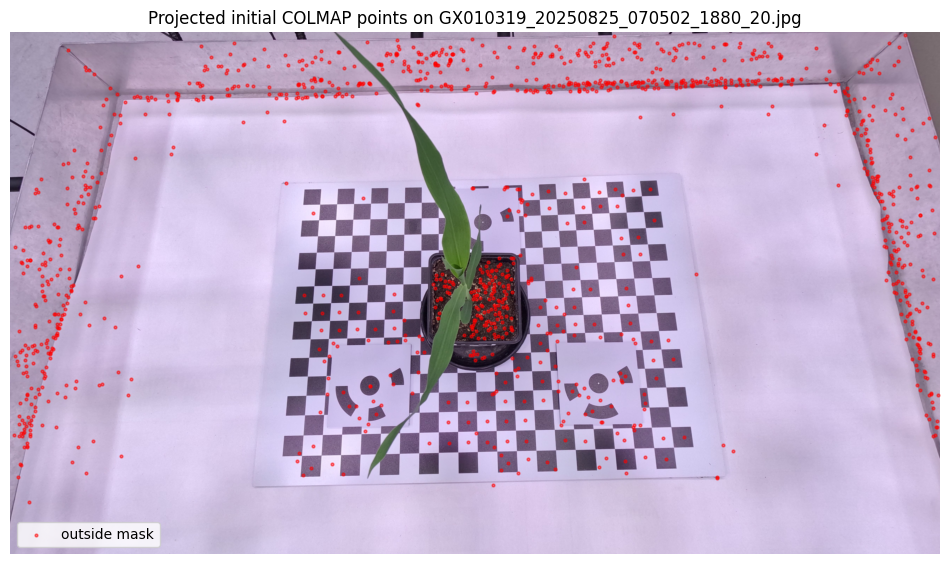

In [ ]:
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# =========================
# PATHS
# =========================
FRAME_DIR = Path("/content/data/frame_1180")
SPARSE_DIR = FRAME_DIR / "sparse" / "0"
IMAGES_DIR = FRAME_DIR / "images"
MASKS_DIR = FRAME_DIR / "masks_binary_gt"

print("FRAME_DIR:", FRAME_DIR)
print("SPARSE_DIR exists:", SPARSE_DIR.exists())
print("IMAGES_DIR exists:", IMAGES_DIR.exists())
print("MASKS_DIR exists:", MASKS_DIR.exists())

# =========================
# LOAD COLMAP RECONSTRUCTION
# =========================
import pycolmap

recon = pycolmap.Reconstruction(str(SPARSE_DIR))
print("num cameras:", len(recon.cameras))
print("num images :", len(recon.images))
print("num points :", len(recon.points3D))

# =========================
# HELPERS
# =========================
def get_mask_path_for_image_name(image_name: str):
    stem = Path(image_name).stem
    return MASKS_DIR / f"{stem}_mask_ground_truth.png"

def load_mask(mask_path):
    arr = np.array(Image.open(mask_path).convert("L"))
    return arr > 127

def get_visible_point3D_ids(image):
    pids = []
    for p2d in image.points2D:
        pid = p2d.point3D_id
        if pid != -1:
            pids.append(pid)
    return pids

def rigid3d_to_matrix(T):
    """
    Convert pycolmap Rigid3d to a numpy matrix robustly across versions.
    Returns either a 3x4 or 4x4 matrix.
    """
    # case 1: matrix() method
    if hasattr(T, "matrix"):
        M = np.array(T.matrix(), dtype=float)
        return M

    # case 2: rotation + translation fields
    if hasattr(T, "rotation") and hasattr(T, "translation"):
        R_obj = T.rotation
        t = np.array(T.translation, dtype=float).reshape(3)

        # try to get rotation matrix robustly
        if hasattr(R_obj, "matrix"):
            R = np.array(R_obj.matrix(), dtype=float)
        elif hasattr(R_obj, "quat"):
            q = np.array(R_obj.quat, dtype=float)  # [w,x,y,z] maybe
            # quaternion to rotation matrix
            w, x, y, z = q
            R = np.array([
                [1 - 2*y*y - 2*z*z, 2*x*y - 2*z*w,     2*x*z + 2*y*w],
                [2*x*y + 2*z*w,     1 - 2*x*x - 2*z*z, 2*y*z - 2*x*w],
                [2*x*z - 2*y*w,     2*y*z + 2*x*w,     1 - 2*x*x - 2*y*y]
            ], dtype=float)
        else:
            raise RuntimeError("Could not extract rotation matrix from Rigid3d.rotation")

        M = np.concatenate([R, t.reshape(3, 1)], axis=1)
        return M

    raise RuntimeError("Unsupported pycolmap Rigid3d API; could not build transform matrix")

def project_point(camera, image, xyz):
    """
    Project a world 3D point into image pixels.
    Returns (x, y) or None.
    """
    T = image.cam_from_world()   # returns Rigid3d in your pycolmap version
    M = rigid3d_to_matrix(T)

    xyz_h = np.concatenate([np.array(xyz, dtype=float), [1.0]])

    if M.shape == (3, 4):
        xyz_cam = M @ xyz_h
    elif M.shape == (4, 4):
        xyz_cam_h = M @ xyz_h
        xyz_cam = xyz_cam_h[:3]
    else:
        raise ValueError(f"Unexpected transform matrix shape: {M.shape}")

    if xyz_cam[2] <= 1e-8:
        return None

    xy = camera.img_from_cam(xyz_cam)
    if xy is None:
        return None

    return float(xy[0]), float(xy[1])

# =========================
# MAIN ANALYSIS
# =========================
total_projections = 0
inside_projections = 0

point_inside_counts = defaultdict(int)
point_total_counts = defaultdict(int)

image_stats = {}

for image_id, image in recon.images.items():
    image_name = image.name
    mask_path = get_mask_path_for_image_name(image_name)

    if not mask_path.exists():
        print("Missing mask for:", image_name)
        continue

    mask = load_mask(mask_path)
    H, W = mask.shape
    cam = recon.cameras[image.camera_id]

    inside_here = 0
    total_here = 0

    pids = get_visible_point3D_ids(image)

    for pid in pids:
        if pid not in recon.points3D:
            continue

        xyz = recon.points3D[pid].xyz
        proj = project_point(cam, image, xyz)
        if proj is None:
            continue

        x, y = proj
        xi, yi = int(round(x)), int(round(y))

        if xi < 0 or xi >= W or yi < 0 or yi >= H:
            continue

        total_projections += 1
        total_here += 1
        point_total_counts[pid] += 1

        if mask[yi, xi]:
            inside_projections += 1
            inside_here += 1
            point_inside_counts[pid] += 1

    image_stats[image_name] = {
        "inside": inside_here,
        "total": total_here,
        "ratio": inside_here / total_here if total_here > 0 else float("nan")
    }

global_inside_ratio = inside_projections / total_projections if total_projections > 0 else np.nan

print("\n====================")
print("GLOBAL STATS")
print("====================")
print("Total valid projections:", total_projections)
print("Inside-mask projections:", inside_projections)
print("Global inside ratio:", global_inside_ratio)

# =========================
# PER-POINT SUMMARY
# =========================
ratios = []
for pid in point_total_counts:
    total = point_total_counts[pid]
    inside = point_inside_counts[pid]
    ratios.append(inside / total)

ratios = np.array(ratios, dtype=float)

print("\n====================")
print("PER-POINT STATS")
print("====================")
print("Number of 3D points evaluated:", len(ratios))
print("Mean inside-view ratio per point:", float(np.mean(ratios)))
print("Median inside-view ratio per point:", float(np.median(ratios)))

for thr in [0.25, 0.5, 0.75, 1.0]:
    count = int(np.sum(ratios >= thr))
    print(f"Points with inside-ratio >= {thr}: {count} / {len(ratios)} ({count/len(ratios):.3f})")

# =========================
# PER-IMAGE TABLE
# =========================
df = pd.DataFrame([
    {"image_name": k, **v}
    for k, v in image_stats.items()
]).sort_values("image_name")

print("\n====================")
print("PER-IMAGE SUMMARY")
print("====================")
display(df)

# =========================
# ONE OVERLAY VISUALIZATION
# =========================
# choose one image
image_id, image = list(recon.images.items())[0]
image_name = image.name

img_path = IMAGES_DIR / image_name
mask_path = get_mask_path_for_image_name(image_name)

img = np.array(Image.open(img_path).convert("RGB"))
mask = load_mask(mask_path)
cam = recon.cameras[image.camera_id]

inside_pts = []
outside_pts = []

for pid in get_visible_point3D_ids(image):
    if pid not in recon.points3D:
        continue

    xyz = recon.points3D[pid].xyz
    proj = project_point(cam, image, xyz)
    if proj is None:
        continue

    x, y = proj
    xi, yi = int(round(x)), int(round(y))

    if xi < 0 or xi >= img.shape[1] or yi < 0 or yi >= img.shape[0]:
        continue

    if mask[yi, xi]:
        inside_pts.append((x, y))
    else:
        outside_pts.append((x, y))

plt.figure(figsize=(12, 8))
plt.imshow(img)

if outside_pts:
    outside_pts = np.array(outside_pts)
    plt.scatter(outside_pts[:, 0], outside_pts[:, 1], s=4, c='red', alpha=0.5, label='outside mask')

if inside_pts:
    inside_pts = np.array(inside_pts)
    plt.scatter(inside_pts[:, 0], inside_pts[:, 1], s=4, c='lime', alpha=0.5, label='inside mask')

plt.legend()
plt.title(f"Projected initial COLMAP points on {image_name}")
plt.axis("off")
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

save_dir = Path("/content/step2_init_diagnosis")
save_dir.mkdir(exist_ok=True)

# Save per-image summary
df.to_csv(save_dir / "per_image_summary.csv", index=False)

# Save global stats
with open(save_dir / "global_stats.txt", "w") as f:
    f.write("STEP 2: INITIALIZATION DIAGNOSIS\n")
    f.write("===============================\n")
    f.write(f"Total valid projections: {total_projections}\n")
    f.write(f"Inside-mask projections: {inside_projections}\n")
    f.write(f"Global inside ratio: {inside_projections / total_projections if total_projections > 0 else np.nan}\n\n")

    f.write(f"Number of 3D points evaluated: {len(ratios)}\n")
    f.write(f"Mean inside-view ratio per point: {float(np.mean(ratios))}\n")
    f.write(f"Median inside-view ratio per point: {float(np.median(ratios))}\n\n")

    for thr in [0.25, 0.5, 0.75, 1.0]:
        count = int(np.sum(ratios >= thr))
        f.write(f"Points with inside-ratio >= {thr}: {count} / {len(ratios)} ({count/len(ratios):.6f})\n")

print("✅ Saved Step 2 stats to", save_dir)

✅ Saved Step 2 stats to /content/step2_init_diagnosis


In [ ]:
%%bash
cd /content
zip -r step2_init_diagnosis.zip step2_init_diagnosis

  adding: step2_init_diagnosis/ (stored 0%)
  adding: step2_init_diagnosis/per_image_summary.csv (deflated 68%)
  adding: step2_init_diagnosis/global_stats.txt (deflated 56%)


In [ ]:
from google.colab import files
files.download("/content/step2_init_diagnosis.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Create a filtered plant-focused initialization from the existing COLMAP points.

In [ ]:
from pathlib import Path
import numpy as np
import open3d as o3d

filtered_points = []
filtered_colors = []
kept_ids = []

# choose threshold:
# keep points that are inside the plant mask in at least 50% of the views where they are observed
THRESH_RATIO = 0.5

for pid in point_total_counts:
    total = point_total_counts[pid]
    inside = point_inside_counts[pid]
    ratio = inside / total

    if ratio >= THRESH_RATIO:
        p = recon.points3D[pid]
        filtered_points.append(np.array(p.xyz, dtype=float))

        # colors are usually uint8 RGB in COLMAP
        if hasattr(p, "color"):
            filtered_colors.append(np.array(p.color, dtype=float) / 255.0)
        else:
            filtered_colors.append(np.array([0.0, 1.0, 0.0], dtype=float))

        kept_ids.append(pid)

filtered_points = np.array(filtered_points)
filtered_colors = np.array(filtered_colors)

print("Original 3D points:", len(recon.points3D))
print("Evaluated points   :", len(point_total_counts))
print("Kept filtered points:", len(filtered_points))

Original 3D points: 8433
Evaluated points   : 8433
Kept filtered points: 16


In [ ]:
from pathlib import Path
import open3d as o3d

save_dir = Path("/content/step3_filtered_init")
save_dir.mkdir(exist_ok=True)

pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(filtered_points)
pcd.colors = o3d.utility.Vector3dVector(filtered_colors)

filtered_ply_path = save_dir / "filtered_points_ratio_0p5.ply"
o3d.io.write_point_cloud(str(filtered_ply_path), pcd)

print("✅ Saved filtered point cloud to:", filtered_ply_path)

✅ Saved filtered point cloud to: /content/step3_filtered_init/filtered_points_ratio_0p5.ply


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

print("Filtered point cloud path:", filtered_ply_path)
print("Number of kept points:", len(filtered_points))

Filtered point cloud path: /content/step3_filtered_init/filtered_points_ratio_0p5.ply
Number of kept points: 16


In [ ]:
import numpy as np

for thr in [0.0, 0.00005, 0.1, 0.2, 0.25, 0.33, 0.5]:
    count = int(np.sum(ratios >= thr))
    print(f"threshold {thr:>4}: {count} points")

threshold  0.0: 8433 points
threshold 5e-05: 16 points
threshold  0.1: 16 points
threshold  0.2: 16 points
threshold 0.25: 16 points
threshold 0.33: 16 points
threshold  0.5: 16 points


In [ ]:
import numpy as np
import open3d as o3d
from PIL import Image
from pathlib import Path
import random

# =========================
# CONFIG
# =========================
NUM_POINTS_PER_IMAGE = 2000   # increase if needed
DEPTH_MIN = 0.3
DEPTH_MAX = 1.0

save_dir = Path("/content/step3_random_init")
save_dir.mkdir(exist_ok=True)

points = []
colors = []

# =========================
# LOOP OVER IMAGES
# =========================
for image_id, image in recon.images.items():
    image_name = image.name

    img_path = IMAGES_DIR / image_name
    mask_path = MASKS_DIR / f"{Path(image_name).stem}_mask_ground_truth.png"

    if not mask_path.exists():
        continue

    img = np.array(Image.open(img_path).convert("RGB"))
    mask = np.array(Image.open(mask_path).convert("L")) > 127

    cam = recon.cameras[image.camera_id]

    # get transform
    T = image.cam_from_world()
    M = np.array(T.matrix())

    # invert transform (camera → world)
    if M.shape == (3,4):
        M = np.vstack([M, [0,0,0,1]])
    M_inv = np.linalg.inv(M)

    H, W = mask.shape

    ys, xs = np.where(mask)

    if len(xs) == 0:
        continue

    idx = np.random.choice(len(xs), size=min(NUM_POINTS_PER_IMAGE, len(xs)), replace=False)

    xs = xs[idx]
    ys = ys[idx]

    for x, y in zip(xs, ys):
        # normalize to camera coords
        # (use COLMAP intrinsics)
        ray = cam.cam_from_img(np.array([x, y]))

        # random depth
        d = np.random.uniform(DEPTH_MIN, DEPTH_MAX)

        pt_cam = np.array([ray[0]*d, ray[1]*d, d, 1.0])

        # transform to world
        pt_world = M_inv @ pt_cam
        pt_world = pt_world[:3]

        points.append(pt_world)

        # color from image
        colors.append(img[y, x] / 255.0)

points = np.array(points)
colors = np.array(colors)

print("Generated plant points:", len(points))

# =========================
# SAVE
# =========================
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(points)
pcd.colors = o3d.utility.Vector3dVector(colors)

out_path = save_dir / "plant_random_init.ply"
o3d.io.write_point_cloud(str(out_path), pcd)

print("✅ Saved new initialization:", out_path)

/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))


Generated plant points: 42000
✅ Saved new initialization: /content/step3_random_init/plant_random_init.ply


In [ ]:
!find /content/data/frame_1180 -name "*.ply" | sort

In [ ]:
from pathlib import Path
import shutil

scene_dir = Path("/content/data/frame_1180")
new_init = Path("/content/step3_random_init/plant_random_init.ply")

# most likely target path
target_ply = scene_dir / "sparse" / "0" / "points3D.ply"

print("New init exists:", new_init.exists())
print("Target ply path :", target_ply)

if not target_ply.exists():
    raise FileNotFoundError(f"Could not find expected target ply at {target_ply}. Run the find command first.")

backup_ply = scene_dir / "sparse" / "0" / "points3D_original_backup.ply"

if not backup_ply.exists():
    shutil.copy2(target_ply, backup_ply)
    print("✅ Backed up original initialization to:", backup_ply)

shutil.copy2(new_init, target_ply)
print("✅ Replaced initialization with plant-focused point cloud")

New init exists: True
Target ply path : /content/data/frame_1180/sparse/0/points3D.ply


FileNotFoundError: Could not find expected target ply at /content/data/frame_1180/sparse/0/points3D.ply. Run the find command first.

In [ ]:
EXPERIMENT_MODE = "alpha"
EXP_NAME = "frame_1180_alpha_gt_plantinit"

print("EXPERIMENT_MODE =", EXPERIMENT_MODE)
print("EXP_NAME        =", EXP_NAME)

EXPERIMENT_MODE = alpha
EXP_NAME        = frame_1180_alpha_gt_plantinit


In [ ]:
import os
import shutil
from pathlib import Path

frame_root = Path("/content/data/frame_1180")
active = frame_root / "masks_binary_active"
gt = frame_root / "masks_binary_gt"

if active.exists() or active.is_symlink():
    active.unlink() if active.is_symlink() else shutil.rmtree(active)

os.symlink(gt, active, target_is_directory=True)

print("✅ Active masks ->", active.resolve())

✅ Active masks -> /content/data/frame_1180/masks_binary_gt


In [ ]:
from pathlib import Path

def patch_loss_mode(mode: str, lambda_mask: float = 0.01):
    path = Path("/content/Wheat-3DGS/train_vanilla_3dgs.py")
    text = path.read_text()

    text = text.replace("lambda_mask = 0.1\n\n", "")
    text = text.replace("lambda_mask = 0.01\n\n", "")

    silhouette_block = """        gt_image = viewpoint_cam.original_image.cuda()
        gt_mask = viewpoint_cam.gt_alpha_mask.cuda()

        Ll1 = l1_loss(image, gt_image)
        rgb_loss = (1.0 - opt.lambda_dssim) * Ll1 + opt.lambda_dssim * (1.0 - ssim(image, gt_image))

        pred_mask = image.abs().sum(dim=0, keepdim=True)
        pred_mask = pred_mask / (pred_mask.max().detach() + 1e-8)
        pred_mask = pred_mask.clamp(0.0, 1.0)

        mask_loss = l1_loss(pred_mask, gt_mask)

        loss = rgb_loss + lambda_mask * mask_loss
"""

    alpha_block = """        gt_image = viewpoint_cam.original_image.cuda()
        Ll1 = l1_loss(image, gt_image)
        loss = (1.0 - opt.lambda_dssim) * Ll1 + opt.lambda_dssim * (1.0 - ssim(image, gt_image))
"""

    if mode in ["normal", "alpha"]:
        if silhouette_block in text:
            text = text.replace(silhouette_block, alpha_block)
    elif mode == "silhouette":
        text = text.replace("def training(", f"lambda_mask = {lambda_mask}\n\ndef training(")
        if alpha_block in text:
            text = text.replace(alpha_block, silhouette_block)
    else:
        raise ValueError("mode must be normal, alpha, or silhouette")

    path.write_text(text)
    print(f"✅ Loss mode -> {mode}")

patch_loss_mode("alpha")

✅ Loss mode -> alpha


In [ ]:
MODEL_DIR = f"/content/output/{EXP_NAME}"
print("MODEL_DIR =", MODEL_DIR)

MODEL_DIR = /content/output/frame_1180_alpha_gt_plantinit


In [ ]:
import numpy as np
from pathlib import Path
from plyfile import PlyData, PlyElement

# We assume these already exist from your previous cell:
# points  -> shape [N, 3]
# colors  -> shape [N, 3] in [0,1]

save_dir = Path("/content/step3_random_init")
save_dir.mkdir(exist_ok=True)

pts = np.asarray(points, dtype=np.float32)
cols = np.asarray(colors, dtype=np.float32)

if cols.max() <= 1.0:
    cols = (cols * 255.0).clip(0, 255).astype(np.uint8)
else:
    cols = cols.clip(0, 255).astype(np.uint8)

normals = np.zeros_like(pts, dtype=np.float32)

vertex_data = np.empty(
    len(pts),
    dtype=[
        ("x", "f4"), ("y", "f4"), ("z", "f4"),
        ("nx", "f4"), ("ny", "f4"), ("nz", "f4"),
        ("red", "u1"), ("green", "u1"), ("blue", "u1"),
    ]
)

vertex_data["x"] = pts[:, 0]
vertex_data["y"] = pts[:, 1]
vertex_data["z"] = pts[:, 2]

vertex_data["nx"] = normals[:, 0]
vertex_data["ny"] = normals[:, 1]
vertex_data["nz"] = normals[:, 2]

vertex_data["red"] = cols[:, 0]
vertex_data["green"] = cols[:, 1]
vertex_data["blue"] = cols[:, 2]

ply_path = save_dir / "plant_random_init_compatible.ply"
PlyData([PlyElement.describe(vertex_data, "vertex")], text=False).write(str(ply_path))

print("✅ Saved compatible PLY to:", ply_path)
print("num points:", len(vertex_data))

✅ Saved compatible PLY to: /content/step3_random_init/plant_random_init_compatible.ply
num points: 42000


In [ ]:
from pathlib import Path
import shutil

scene_dir = Path("/content/data/frame_1180")
new_init = Path("/content/step3_random_init/plant_random_init_compatible.ply")
target_ply = scene_dir / "sparse" / "0" / "points3D.ply"

print("new init exists:", new_init.exists())
print("target ply:", target_ply)

shutil.copy2(new_init, target_ply)
print("✅ Replaced points3D.ply with compatible plant-focused initialization")

new init exists: True
target ply: /content/data/frame_1180/sparse/0/points3D.ply
✅ Replaced points3D.ply with compatible plant-focused initialization


In [ ]:
from plyfile import PlyData

ply = PlyData.read("/content/data/frame_1180/sparse/0/points3D.ply")
print(ply)
print("vertex count:", len(ply["vertex"].data))
print("fields:", ply["vertex"].data.dtype.names)

ply
format binary_little_endian 1.0
element vertex 42000
property float x
property float y
property float z
property float nx
property float ny
property float nz
property uchar red
property uchar green
property uchar blue
end_header
vertex count: 42000
fields: ('x', 'y', 'z', 'nx', 'ny', 'nz', 'red', 'green', 'blue')


In [ ]:
EXP_NAME = "frame_1180_alpha_gt_plantinit"
ITERATIONS = 15000
print("EXP_NAME =", EXP_NAME)

EXP_NAME = frame_1180_alpha_gt_plantinit


In [ ]:
import os
import shutil
from pathlib import Path

frame_root = Path("/content/data/frame_1180")
active = frame_root / "masks_binary_active"
gt = frame_root / "masks_binary_gt"

if active.exists() or active.is_symlink():
    active.unlink() if active.is_symlink() else shutil.rmtree(active)

os.symlink(gt, active, target_is_directory=True)

print("✅ Active masks ->", active.resolve())

✅ Active masks -> /content/data/frame_1180/masks_binary_gt


In [ ]:
from pathlib import Path

path = Path("/content/Wheat-3DGS/train_vanilla_3dgs.py")
text = path.read_text()

text = text.replace("lambda_mask = 0.1\n\n", "")
text = text.replace("lambda_mask = 0.01\n\n", "")

silhouette_block = """        gt_image = viewpoint_cam.original_image.cuda()
        gt_mask = viewpoint_cam.gt_alpha_mask.cuda()

        Ll1 = l1_loss(image, gt_image)
        rgb_loss = (1.0 - opt.lambda_dssim) * Ll1 + opt.lambda_dssim * (1.0 - ssim(image, gt_image))

        pred_mask = image.abs().sum(dim=0, keepdim=True)
        pred_mask = pred_mask / (pred_mask.max().detach() + 1e-8)
        pred_mask = pred_mask.clamp(0.0, 1.0)

        mask_loss = l1_loss(pred_mask, gt_mask)

        loss = rgb_loss + lambda_mask * mask_loss
"""

alpha_block = """        gt_image = viewpoint_cam.original_image.cuda()
        Ll1 = l1_loss(image, gt_image)
        loss = (1.0 - opt.lambda_dssim) * Ll1 + opt.lambda_dssim * (1.0 - ssim(image, gt_image))
"""

if silhouette_block in text:
    text = text.replace(silhouette_block, alpha_block)

path.write_text(text)
print("✅ Loss mode set to alpha-only")

✅ Loss mode set to alpha-only


In [ ]:
!grep -n "lambda_mask" /content/Wheat-3DGS/train_vanilla_3dgs.py || true
!grep -n "mask_loss" /content/Wheat-3DGS/train_vanilla_3dgs.py || true

In [ ]:
MODEL_DIR = f"/content/output/{EXP_NAME}"
print("MODEL_DIR =", MODEL_DIR)

MODEL_DIR = /content/output/frame_1180_alpha_gt_plantinit


In [ ]:
%%bash -s "$MODEL_DIR"
set -e

MODEL_DIR="$1"

cd /content/Wheat-3DGS

export CUDA_HOME=/usr/local/cuda
export PATH=$CUDA_HOME/bin:$PATH
export LD_LIBRARY_PATH=$CUDA_HOME/lib64:$LD_LIBRARY_PATH

TORCH_LIB=$(python -c "import os, torch; print(os.path.join(os.path.dirname(torch.__file__), 'lib'))")
export LD_LIBRARY_PATH=$TORCH_LIB:$LD_LIBRARY_PATH

export PYTHONPATH=/content/Wheat-3DGS:/content/Wheat-3DGS/submodules/simple-knn:/content/Wheat-3DGS/submodules/diff-gaussian-rasterization:/content/Wheat-3DGS/submodules/flashsplat-rasterization:$PYTHONPATH

export WANDB_MODE=disabled
export WANDB_DISABLED=true

SCENE="/content/data/frame_1180"
MODEL="$MODEL_DIR"

rm -rf "$MODEL"

python -u train_vanilla_3dgs.py \
  -s "$SCENE" \
  -m "$MODEL" \
  --resolution 4 \
  --iterations 15000

python -u render.py \
  -s "$SCENE" \
  -m "$MODEL" \
  --iteration 15000

Optimizing /content/output/frame_1180_alpha_gt_plantinit
Output folder: /content/output/frame_1180_alpha_gt_plantinit [30/03 20:31:27]
No directory of saved bounding boxes found! [30/03 20:31:27]
No directory of saved segmentation masks found! [30/03 20:31:27]
Reading camera 21/21 [30/03 20:31:27]
Train Cam list with 16 cams: ['GX010009_20250825_070502_1880_0', 'GX010030_20250825_070502_1880_1', 'GX010046_20250825_070502_1880_2', 'GX010051_20250825_070502_1880_3', 'GX010059_20250825_070502_1880_4', 'GX010062_20250825_070502_1880_5', 'GX010067_20250825_070502_1880_6', 'GX010068_20250825_070502_1880_7', 'GX010070_20250825_070502_1880_8', 'GX010078_20250825_070502_1880_9', 'GX010081_20250825_070502_1880_10', 'GX010089_20250825_070502_1880_11', 'GX010102_20250825_070502_1880_12', 'GX010127_20250825_070502_1880_13', 'GX010134_20250825_070502_1880_14', 'GX010141_20250825_070502_1880_15'] [30/03 20:31:27]
Test Cam list with 5 cams: ['GX010148_20250825_070503_1880_16', 'GX010156_20250825_07050

2026-03-30 20:31:20.284070: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1774902680.318498   36297 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1774902680.327028   36297 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1774902680.345175   36297 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774902680.345198   36297 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774902680.345201   36297 computation_placer.cc:177] computation placer alr

In [ ]:
import os
import numpy as np
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import torch
import lpips

ITERATIONS = 15000
MODEL_DIR = "/content/output/frame_1180_alpha_gt_plantinit"

render_dir = os.path.join(MODEL_DIR, f"test/ours_{ITERATIONS}/renders")
gt_dir = os.path.join(MODEL_DIR, f"test/ours_{ITERATIONS}/gt")

render_files = sorted([f for f in os.listdir(render_dir) if f.endswith(".png")])

psnrs, ssims, lpips_vals = [], [], []
device = "cuda" if torch.cuda.is_available() else "cpu"
loss_fn = lpips.LPIPS(net="vgg").to(device)

for f in render_files:
    render_img = Image.open(os.path.join(render_dir, f)).convert("RGB")
    gt_img = Image.open(os.path.join(gt_dir, f)).convert("RGB")

    render_np = np.array(render_img)
    gt_np = np.array(gt_img)

    psnrs.append(peak_signal_noise_ratio(gt_np, render_np, data_range=255))
    ssims.append(structural_similarity(gt_np, render_np, channel_axis=2, data_range=255))

    render_lp = render_img.resize((512, 512))
    gt_lp = gt_img.resize((512, 512))

    render_t = torch.tensor(np.array(render_lp)).permute(2, 0, 1).float()/127.5 - 1
    gt_t = torch.tensor(np.array(gt_lp)).permute(2, 0, 1).float()/127.5 - 1

    render_t = render_t.unsqueeze(0).to(device)
    gt_t = gt_t.unsqueeze(0).to(device)

    with torch.no_grad():
        lpips_vals.append(loss_fn(render_t, gt_t).item())

print("\n=== PLANT-INIT ALPHA METRICS ===")
print("Mean PSNR:", float(np.mean(psnrs)))
print("Mean SSIM:", float(np.mean(ssims)))
print("Mean LPIPS:", float(np.mean(lpips_vals)))

KeyboardInterrupt: 

In [ ]:
%%bash
set -e
cd /content
zip -r frame_1180_alpha_gt_plantinit.zip output/frame_1180_alpha_gt_plantinit

  adding: output/frame_1180_alpha_gt_plantinit/ (stored 0%)
  adding: output/frame_1180_alpha_gt_plantinit/chkpnt7000.pth (deflated 11%)
  adding: output/frame_1180_alpha_gt_plantinit/test/ (stored 0%)
  adding: output/frame_1180_alpha_gt_plantinit/test/ours_15000/ (stored 0%)
  adding: output/frame_1180_alpha_gt_plantinit/test/ours_15000/renders/ (stored 0%)
  adding: output/frame_1180_alpha_gt_plantinit/test/ours_15000/renders/00000.png (deflated 16%)
  adding: output/frame_1180_alpha_gt_plantinit/test/ours_15000/renders/00003.png (deflated 13%)
  adding: output/frame_1180_alpha_gt_plantinit/test/ours_15000/renders/00002.png (deflated 13%)
  adding: output/frame_1180_alpha_gt_plantinit/test/ours_15000/renders/00001.png (deflated 13%)
  adding: output/frame_1180_alpha_gt_plantinit/test/ours_15000/renders/00004.png (deflated 12%)
  adding: output/frame_1180_alpha_gt_plantinit/test/ours_15000/gt/ (stored 0%)
  adding: output/frame_1180_alpha_gt_plantinit/test/ours_15000/gt/00000.png (de

In [ ]:
from google.colab import files
files.download("/content/frame_1180_alpha_gt_plantinit.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
import shutil

scene_dir = Path("/content/data/frame_1180/sparse/0")
backup_ply = scene_dir / "points3D_original_backup.ply"
target_ply = scene_dir / "points3D.ply"

shutil.copy2(backup_ply, target_ply)
print("✅ Restored original COLMAP initialization")



FileNotFoundError: [Errno 2] No such file or directory: '/content/data/frame_1180/sparse/0/points3D_original_backup.ply'

In [ ]:
!grep -R "densify" -n /content/Wheat-3DGS | head -50
!grep -R "grad_threshold" -n /content/Wheat-3DGS | head -50
!grep -R "prune" -n /content/Wheat-3DGS | head -50


/content/Wheat-3DGS/scene/gaussian_model.py:399:    def densify_and_split(self, grads, grad_threshold, scene_extent, N=2):
/content/Wheat-3DGS/scene/gaussian_model.py:427:    def densify_and_clone(self, grads, grad_threshold, scene_extent):
/content/Wheat-3DGS/scene/gaussian_model.py:445:    def densify_and_prune(self, max_grad, min_opacity, extent, max_screen_size):
/content/Wheat-3DGS/scene/gaussian_model.py:449:        self.densify_and_clone(grads, max_grad, extent)
/content/Wheat-3DGS/scene/gaussian_model.py:450:        self.densify_and_split(grads, max_grad, extent)
/content/Wheat-3DGS/test.py:63:            if iteration < opt.densify_until_iter:
/content/Wheat-3DGS/test.py:68:                if iteration > opt.densify_from_iter and iteration % opt.densification_interval == 0:
/content/Wheat-3DGS/test.py:70:                    gaussians.densify_and_prune(opt.densify_grad_threshold, 0.005, scene.cameras_extent, size_threshold)
/content/Wheat-3DGS/test.py:71:                if itera

In [ ]:
import os
import shutil
from pathlib import Path

frame_root = Path("/content/data/frame_1180")
active = frame_root / "masks_binary_active"
gt = frame_root / "masks_binary_gt"

if active.exists() or active.is_symlink():
    active.unlink() if active.is_symlink() else shutil.rmtree(active)

os.symlink(gt, active, target_is_directory=True)

print("✅ Active masks ->", active.resolve())

✅ Active masks -> /content/data/frame_1180/masks_binary_gt


In [ ]:
from pathlib import Path

path = Path("/content/Wheat-3DGS/train_vanilla_3dgs.py")
text = path.read_text()

text = text.replace("lambda_mask = 0.1\n\n", "")
text = text.replace("lambda_mask = 0.01\n\n", "")

silhouette_block = """        gt_image = viewpoint_cam.original_image.cuda()
        gt_mask = viewpoint_cam.gt_alpha_mask.cuda()

        Ll1 = l1_loss(image, gt_image)
        rgb_loss = (1.0 - opt.lambda_dssim) * Ll1 + opt.lambda_dssim * (1.0 - ssim(image, gt_image))

        pred_mask = image.abs().sum(dim=0, keepdim=True)
        pred_mask = pred_mask / (pred_mask.max().detach() + 1e-8)
        pred_mask = pred_mask.clamp(0.0, 1.0)

        mask_loss = l1_loss(pred_mask, gt_mask)

        loss = rgb_loss + lambda_mask * mask_loss
"""

alpha_block = """        gt_image = viewpoint_cam.original_image.cuda()
        Ll1 = l1_loss(image, gt_image)
        loss = (1.0 - opt.lambda_dssim) * Ll1 + opt.lambda_dssim * (1.0 - ssim(image, gt_image))
"""

if silhouette_block in text:
    text = text.replace(silhouette_block, alpha_block)

path.write_text(text)
print("✅ Loss mode set to alpha-only")

✅ Loss mode set to alpha-only


In [ ]:
!grep -R "densify" -n /content/Wheat-3DGS | head -50
!grep -R "grad_threshold" -n /content/Wheat-3DGS | head -50

/content/Wheat-3DGS/scene/gaussian_model.py:399:    def densify_and_split(self, grads, grad_threshold, scene_extent, N=2):
/content/Wheat-3DGS/scene/gaussian_model.py:427:    def densify_and_clone(self, grads, grad_threshold, scene_extent):
/content/Wheat-3DGS/scene/gaussian_model.py:445:    def densify_and_prune(self, max_grad, min_opacity, extent, max_screen_size):
/content/Wheat-3DGS/scene/gaussian_model.py:449:        self.densify_and_clone(grads, max_grad, extent)
/content/Wheat-3DGS/scene/gaussian_model.py:450:        self.densify_and_split(grads, max_grad, extent)
/content/Wheat-3DGS/test.py:63:            if iteration < opt.densify_until_iter:
/content/Wheat-3DGS/test.py:68:                if iteration > opt.densify_from_iter and iteration % opt.densification_interval == 0:
/content/Wheat-3DGS/test.py:70:                    gaussians.densify_and_prune(opt.densify_grad_threshold, 0.005, scene.cameras_extent, size_threshold)
/content/Wheat-3DGS/test.py:71:                if itera

In [ ]:
from pathlib import Path
import re

path = Path("/content/Wheat-3DGS/arguments/__init__.py")
text = path.read_text()

old = "self.densify_grad_threshold = 0.0002"
new = "self.densify_grad_threshold = 0.0001"

if old not in text:
    raise ValueError("Could not find the expected densify_grad_threshold line.")

text = text.replace(old, new)
path.write_text(text)

print("✅ Patched densify_grad_threshold from 0.0002 to 0.0001")

✅ Patched densify_grad_threshold from 0.0002 to 0.0001


In [ ]:
!grep -n "densify_grad_threshold" /content/Wheat-3DGS/arguments/__init__.py

88:        self.densify_grad_threshold = 0.0001


In [ ]:
from pathlib import Path
import shutil

scene_dir = Path("/content/data/frame_1180/sparse/0")
backup_ply = scene_dir / "points3D_original_backup.ply"
target_ply = scene_dir / "points3D.ply"

if not backup_ply.exists():
    raise FileNotFoundError(f"Backup file not found: {backup_ply}")

shutil.copy2(backup_ply, target_ply)
print("✅ Restored original COLMAP initialization")

FileNotFoundError: Backup file not found: /content/data/frame_1180/sparse/0/points3D_original_backup.ply

In [ ]:
import os
import shutil
from pathlib import Path

frame_root = Path("/content/data/frame_1180")
active = frame_root / "masks_binary_active"
gt = frame_root / "masks_binary_gt"

if active.exists() or active.is_symlink():
    active.unlink() if active.is_symlink() else shutil.rmtree(active)

os.symlink(gt, active, target_is_directory=True)

print("✅ Active masks ->", active.resolve())

✅ Active masks -> /content/data/frame_1180/masks_binary_gt


In [ ]:
EXP_NAME = "frame_1180_alpha_gt_dense"
MODEL_DIR = f"/content/output/{EXP_NAME}"
ITERATIONS = 15000

print("EXP_NAME =", EXP_NAME)
print("MODEL_DIR =", MODEL_DIR)

EXP_NAME = frame_1180_alpha_gt_dense
MODEL_DIR = /content/output/frame_1180_alpha_gt_dense


In [ ]:
%%bash -s "$MODEL_DIR"
set -e

MODEL_DIR="$1"

cd /content/Wheat-3DGS

export CUDA_HOME=/usr/local/cuda
export PATH=$CUDA_HOME/bin:$PATH
export LD_LIBRARY_PATH=$CUDA_HOME/lib64:$LD_LIBRARY_PATH

TORCH_LIB=$(python -c "import os, torch; print(os.path.join(os.path.dirname(torch.__file__), 'lib'))")
export LD_LIBRARY_PATH=$TORCH_LIB:$LD_LIBRARY_PATH

export PYTHONPATH=/content/Wheat-3DGS:/content/Wheat-3DGS/submodules/simple-knn:/content/Wheat-3DGS/submodules/diff-gaussian-rasterization:/content/Wheat-3DGS/submodules/flashsplat-rasterization:$PYTHONPATH

export WANDB_MODE=disabled
export WANDB_DISABLED=true

SCENE="/content/data/frame_1180"
MODEL="$MODEL_DIR"

rm -rf "$MODEL"

python -u train_vanilla_3dgs.py \
  -s "$SCENE" \
  -m "$MODEL" \
  --resolution 4 \
  --iterations 15000

python -u render.py \
  -s "$SCENE" \
  -m "$MODEL" \
  --iteration 15000

Process is terminated.


In [ ]:
import os
import numpy as np
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import torch
import lpips

MODEL_DIR = "/content/output/frame_1180_alpha_gt_dense"
render_dir = os.path.join(MODEL_DIR, f"test/ours_{ITERATIONS}/renders")
gt_dir = os.path.join(MODEL_DIR, f"test/ours_{ITERATIONS}/gt")

render_files = sorted([f for f in os.listdir(render_dir) if f.endswith(".png")])

psnrs, ssims, lpips_vals = [], [], []
device = "cuda" if torch.cuda.is_available() else "cpu"
loss_fn = lpips.LPIPS(net="vgg").to(device)

for f in render_files:
    render_img = Image.open(os.path.join(render_dir, f)).convert("RGB")
    gt_img = Image.open(os.path.join(gt_dir, f)).convert("RGB")

    render_np = np.array(render_img)
    gt_np = np.array(gt_img)

    psnrs.append(peak_signal_noise_ratio(gt_np, render_np, data_range=255))
    ssims.append(structural_similarity(gt_np, render_np, channel_axis=2, data_range=255))

    render_lp = render_img.resize((512, 512))
    gt_lp = gt_img.resize((512, 512))

    render_t = torch.tensor(np.array(render_lp)).permute(2, 0, 1).float()/127.5 - 1
    gt_t = torch.tensor(np.array(gt_lp)).permute(2, 0, 1).float()/127.5 - 1

    render_t = render_t.unsqueeze(0).to(device)
    gt_t = gt_t.unsqueeze(0).to(device)

    with torch.no_grad():
        lpips_vals.append(loss_fn(render_t, gt_t).item())

print("\n=== DENSE ALPHA METRICS ===")
print("Mean PSNR:", float(np.mean(psnrs)))
print("Mean SSIM:", float(np.mean(ssims)))
print("Mean LPIPS:", float(np.mean(lpips_vals)))

KeyboardInterrupt: 

In [ ]:
metrics_text = f"""Experiment: frame_1180_alpha_gt_dense

Mean PSNR: {float(np.mean(psnrs))}
Mean SSIM: {float(np.mean(ssims))}
Mean LPIPS: {float(np.mean(lpips_vals))}
"""

with open("/content/frame_1180_alpha_gt_dense_metrics.txt", "w") as f:
    f.write(metrics_text)

print("✅ Saved metrics txt")

✅ Saved metrics txt


In [ ]:
%%bash
set -e
cd /content
zip -r frame_1180_alpha_gt_dense.zip output/frame_1180_alpha_gt_dense

  adding: output/frame_1180_alpha_gt_dense/ (stored 0%)
  adding: output/frame_1180_alpha_gt_dense/chkpnt7000.pth (deflated 10%)
  adding: output/frame_1180_alpha_gt_dense/events.out.tfevents.1774906775.94d36dfd0a07.53808.0 (deflated 60%)
  adding: output/frame_1180_alpha_gt_dense/test/ (stored 0%)
  adding: output/frame_1180_alpha_gt_dense/test/ours_15000/ (stored 0%)
  adding: output/frame_1180_alpha_gt_dense/test/ours_15000/renders/ (stored 0%)
  adding: output/frame_1180_alpha_gt_dense/test/ours_15000/renders/00000.png (deflated 15%)
  adding: output/frame_1180_alpha_gt_dense/test/ours_15000/renders/00003.png (deflated 12%)
  adding: output/frame_1180_alpha_gt_dense/test/ours_15000/renders/00002.png (deflated 13%)
  adding: output/frame_1180_alpha_gt_dense/test/ours_15000/renders/00001.png (deflated 12%)
  adding: output/frame_1180_alpha_gt_dense/test/ours_15000/renders/00004.png (deflated 11%)
  adding: output/frame_1180_alpha_gt_dense/test/ours_15000/gt/ (stored 0%)
  adding: out

In [ ]:
from google.colab import files
files.download("/content/frame_1180_alpha_gt_dense.zip")
files.download("/content/frame_1180_alpha_gt_dense_metrics.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!grep -o "Num_points=[0-9]*" /content/frame_1180_alpha_gt_dense_train.log | tail -1

grep: /content/frame_1180_alpha_gt_dense_train.log: No such file or directory


In [ ]:
from plyfile import PlyData

ply_path = "/content/output/frame_1180_alpha_gt_dense/point_cloud/iteration_15000/point_cloud.ply"
ply = PlyData.read(ply_path)

n_gaussians = len(ply["vertex"].data)
print("Final number of gaussians:", n_gaussians)

FileNotFoundError: [Errno 2] No such file or directory: '/content/output/frame_1180_alpha_gt_dense/point_cloud/iteration_15000/point_cloud.ply'

In [ ]:
from pathlib import Path
import shutil

scene_dir = Path("/content/data/frame_1180/sparse/0")
backup_ply = scene_dir / "points3D_original_backup.ply"
target_ply = scene_dir / "points3D.ply"

if not backup_ply.exists():
    raise FileNotFoundError(f"Backup file not found: {backup_ply}")

shutil.copy2(backup_ply, target_ply)
print("✅ Restored original COLMAP initialization")
print("Using:", target_ply)

FileNotFoundError: Backup file not found: /content/data/frame_1180/sparse/0/points3D_original_backup.ply

In [ ]:
import os
import shutil
from pathlib import Path

frame_root = Path("/content/data/frame_1180")
active = frame_root / "masks_binary_active"
gt = frame_root / "masks_binary_gt"

if active.exists() or active.is_symlink():
    active.unlink() if active.is_symlink() else shutil.rmtree(active)

os.symlink(gt, active, target_is_directory=True)

print("✅ Active masks ->", active.resolve())

✅ Active masks -> /content/data/frame_1180/masks_binary_gt


In [ ]:
from pathlib import Path

path = Path("/content/Wheat-3DGS/arguments/__init__.py")
text = path.read_text()

old = "self.densify_grad_threshold = 0.0002"
new = "self.densify_grad_threshold = 0.0001"

if old not in text and new not in text:
    raise ValueError("Could not find densify_grad_threshold line.")

text = text.replace(old, new)
path.write_text(text)

print("✅ densify_grad_threshold is set to 0.0001")

✅ densify_grad_threshold is set to 0.0001


In [ ]:
from pathlib import Path

path = Path("/content/Wheat-3DGS/train_vanilla_3dgs.py")
text = path.read_text()

# remove any old lambda declarations first
text = text.replace("lambda_mask = 0.1\n\n", "")
text = text.replace("lambda_mask = 0.01\n\n", "")

alpha_block = """        gt_image = viewpoint_cam.original_image.cuda()
        Ll1 = l1_loss(image, gt_image)
        loss = (1.0 - opt.lambda_dssim) * Ll1 + opt.lambda_dssim * (1.0 - ssim(image, gt_image))
"""

silhouette_block = """        gt_image = viewpoint_cam.original_image.cuda()
        gt_mask = viewpoint_cam.gt_alpha_mask.cuda()

        Ll1 = l1_loss(image, gt_image)
        rgb_loss = (1.0 - opt.lambda_dssim) * Ll1 + opt.lambda_dssim * (1.0 - ssim(image, gt_image))

        pred_mask = image.abs().sum(dim=0, keepdim=True)
        pred_mask = pred_mask / (pred_mask.max().detach() + 1e-8)
        pred_mask = pred_mask.clamp(0.0, 1.0)

        mask_loss = l1_loss(pred_mask, gt_mask)

        loss = rgb_loss + lambda_mask * mask_loss
"""

if silhouette_block not in text:
    if alpha_block not in text:
        raise ValueError("Could not find alpha block to replace.")
    text = text.replace(alpha_block, silhouette_block)

text = text.replace("def training(", "lambda_mask = 0.01\n\ndef training(")

path.write_text(text)
print("✅ Loss mode set to silhouette with lambda_mask = 0.01")

✅ Loss mode set to silhouette with lambda_mask = 0.01


In [ ]:
EXP_NAME = "frame_1180_alpha_silhouette_gt_dense"
MODEL_DIR = f"/content/output/{EXP_NAME}"
ITERATIONS = 15000

print("EXP_NAME =", EXP_NAME)
print("MODEL_DIR =", MODEL_DIR)

EXP_NAME = frame_1180_alpha_silhouette_gt_dense
MODEL_DIR = /content/output/frame_1180_alpha_silhouette_gt_dense


In [ ]:
# Check for plant-pixels only loss

In [ ]:
from pathlib import Path

active = Path("/content/data/frame_1180/masks_binary_active")
print("active exists:", active.exists())
print("active resolves to:", active.resolve() if active.exists() else "missing")

active exists: True
active resolves to: /content/data/frame_1180/masks_binary_gt


sample mask: GX010009_20250825_070502_1880_0_mask_ground_truth.png
unique values: [  0 255]


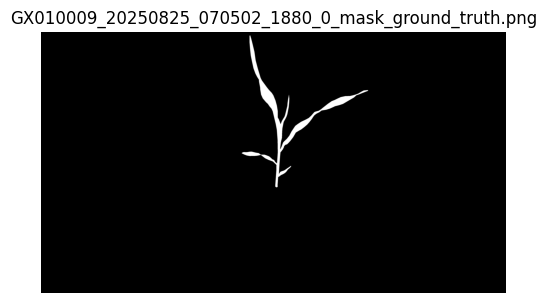

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

mask_dir = Path("/content/data/frame_1180/masks_binary_gt")
sample_mask = sorted(mask_dir.glob("*.png"))[0]

mask = np.array(Image.open(sample_mask).convert("L"))
print("sample mask:", sample_mask.name)
print("unique values:", np.unique(mask))

plt.figure(figsize=(6,6))
plt.imshow(mask, cmap="gray")
plt.title(sample_mask.name)
plt.axis("off")
plt.show()

In [ ]:
!grep -n "masks_binary_active" /content/Wheat-3DGS/scene/dataset_readers.py

107:        alpha_mask_path = os.path.join(os.path.dirname(images_folder), "masks_binary_active", image_name + "_mask_ground_truth.png")


In [ ]:
!grep -n 'getattr(cam_info, "alpha_mask_path", None)' /content/Wheat-3DGS/utils/camera_utils.py
!grep -n "alpha_resized" /content/Wheat-3DGS/utils/camera_utils.py

In [ ]:
!grep -n "self.gt_alpha_mask" /content/Wheat-3DGS/scene/cameras.py
!grep -n "self.original_image \\*= self.gt_alpha_mask" /content/Wheat-3DGS/scene/cameras.py

46:            self.gt_alpha_mask = gt_alpha_mask.to(self.data_device)
48:            self.gt_alpha_mask = torch.ones((1, self.image_height, self.image_width), device=self.data_device)
50:        self.original_image *= self.gt_alpha_mask
50:        self.original_image *= self.gt_alpha_mask


/usr/local/lib/python3.12/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))


image: GX010009_20250825_070502_1880_0.jpg
mask: GX010009_20250825_070502_1880_0_mask_ground_truth.png
mask foreground pixels: 166712
mask total pixels: 15772800


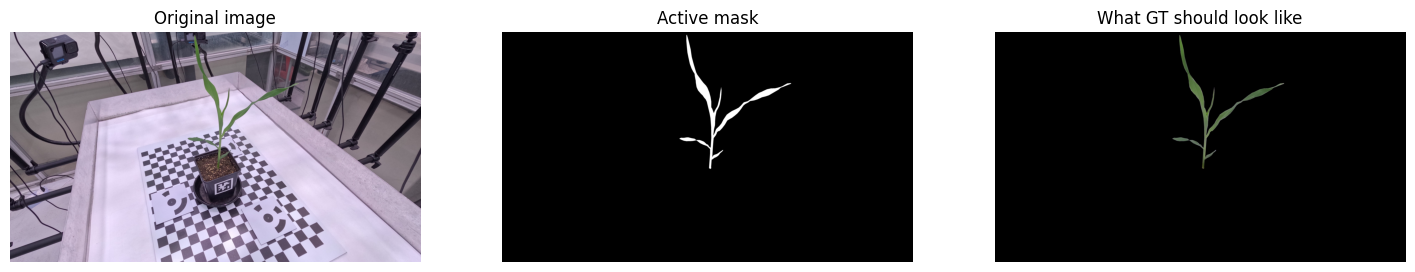

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

images_dir = Path("/content/data/frame_1180/images")
active_masks_dir = Path("/content/data/frame_1180/masks_binary_active")

img_path = sorted(images_dir.glob("*.jpg"))[0]
mask_path = active_masks_dir / f"{img_path.stem}_mask_ground_truth.png"

img = np.array(Image.open(img_path).convert("RGB"))
mask = np.array(Image.open(mask_path).convert("L")) > 127

masked_img = img.copy()
masked_img[~mask] = 0

print("image:", img_path.name)
print("mask:", mask_path.name)
print("mask foreground pixels:", int(mask.sum()))
print("mask total pixels:", int(mask.size))

fig, axs = plt.subplots(1, 3, figsize=(18, 6))
axs[0].imshow(img)
axs[0].set_title("Original image")
axs[0].axis("off")

axs[1].imshow(mask, cmap="gray")
axs[1].set_title("Active mask")
axs[1].axis("off")

axs[2].imshow(masked_img)
axs[2].set_title("What GT should look like")
axs[2].axis("off")

plt.show()

In [ ]:
from pathlib import Path

path = Path("/content/Wheat-3DGS/utils/camera_utils.py")
text = path.read_text()

# ensure imports exist
if "from PIL import Image" not in text:
    text = text.replace("import numpy as np\n", "import numpy as np\nfrom PIL import Image\n")
if "import torch" not in text:
    text = text.replace("from PIL import Image\n", "from PIL import Image\nimport torch\n")

old_block = """    gt_image = resized_image_rgb[:3, ...]
    loaded_mask = None

    if resized_image_rgb.shape[1] == 4:
        loaded_mask = resized_image_rgb[3:4, ...]

    return Camera(colmap_id=cam_info.uid, R=cam_info.R, T=cam_info.T,
                  FoVx=cam_info.FovX, FoVy=cam_info.FovY,
                  image=gt_image, gt_alpha_mask=loaded_mask,
                  image_name=cam_info.image_name, uid=id, data_device=args.data_device,
                  bbox_path=cam_info.bbox_path, mask_paths=cam_info.mask_paths, resolution=resolution, resolution_scale=scale)
"""

new_block = """    gt_image = resized_image_rgb[:3, ...]
    loaded_mask = None

    if getattr(cam_info, "alpha_mask_path", None) is not None:
        alpha_pil = Image.open(cam_info.alpha_mask_path).convert("L")
        alpha_resized = alpha_pil.resize(resolution, Image.NEAREST)
        alpha_np = np.array(alpha_resized)
        alpha_np = (alpha_np > 128).astype(np.float32)
        loaded_mask = torch.from_numpy(alpha_np).unsqueeze(0)
    elif resized_image_rgb.shape[1] == 4:
        loaded_mask = resized_image_rgb[3:4, ...]

    return Camera(colmap_id=cam_info.uid, R=cam_info.R, T=cam_info.T,
                  FoVx=cam_info.FovX, FoVy=cam_info.FovY,
                  image=gt_image, gt_alpha_mask=loaded_mask,
                  image_name=cam_info.image_name, uid=id, data_device=args.data_device,
                  bbox_path=cam_info.bbox_path, mask_paths=cam_info.mask_paths, resolution=resolution, resolution_scale=scale)
"""

if 'getattr(cam_info, "alpha_mask_path", None)' not in text:
    if old_block not in text:
        raise ValueError("Expected block not found in camera_utils.py")
    text = text.replace(old_block, new_block)

path.write_text(text)
print("✅ camera_utils.py patched")

✅ camera_utils.py patched


In [ ]:
!grep -n 'getattr(cam_info, "alpha_mask_path", None)' /content/Wheat-3DGS/utils/camera_utils.py
!grep -n "alpha_resized" /content/Wheat-3DGS/utils/camera_utils.py

49:    if getattr(cam_info, "alpha_mask_path", None) is not None:
51:        alpha_resized = alpha_pil.resize(resolution, Image.NEAREST)
52:        alpha_np = np.array(alpha_resized)


In [ ]:
!grep -n "masks_binary_active" /content/Wheat-3DGS/scene/dataset_readers.py
!grep -n "alpha_mask_path" /content/Wheat-3DGS/scene/dataset_readers.py

107:        alpha_mask_path = os.path.join(os.path.dirname(images_folder), "masks_binary_active", image_name + "_mask_ground_truth.png")
42:    alpha_mask_path: str
107:        alpha_mask_path = os.path.join(os.path.dirname(images_folder), "masks_binary_active", image_name + "_mask_ground_truth.png")
108:        alpha_mask_path = os.path.normpath(alpha_mask_path)
109:        if not os.path.exists(alpha_mask_path):
110:            alpha_mask_path = None
127:                              bbox_path=bbox_path, mask_paths=mask_paths, alpha_mask_path=alpha_mask_path)


In [ ]:
%%bash -s "$MODEL_DIR"
set -e

MODEL_DIR="$1"

cd /content/Wheat-3DGS

export CUDA_HOME=/usr/local/cuda
export PATH=$CUDA_HOME/bin:$PATH
export LD_LIBRARY_PATH=$CUDA_HOME/lib64:$LD_LIBRARY_PATH

TORCH_LIB=$(python -c "import os, torch; print(os.path.join(os.path.dirname(torch.__file__), 'lib'))")
export LD_LIBRARY_PATH=$TORCH_LIB:$LD_LIBRARY_PATH

export PYTHONPATH=/content/Wheat-3DGS:/content/Wheat-3DGS/submodules/simple-knn:/content/Wheat-3DGS/submodules/diff-gaussian-rasterization:/content/Wheat-3DGS/submodules/flashsplat-rasterization:$PYTHONPATH

export WANDB_MODE=disabled
export WANDB_DISABLED=true

SCENE="/content/data/frame_1180"
MODEL="$MODEL_DIR"

rm -rf "$MODEL"

python -u train_vanilla_3dgs.py \
  -s "$SCENE" \
  -m "$MODEL" \
  --resolution 4 \
  --iterations 15000

python -u render.py \
  -s "$SCENE" \
  -m "$MODEL" \
  --iteration 15000

Optimizing /content/output/frame_1180_alpha_silhouette_gt_dense
Output folder: /content/output/frame_1180_alpha_silhouette_gt_dense [01/04 11:19:34]
No directory of saved bounding boxes found! [01/04 11:19:34]
No directory of saved segmentation masks found! [01/04 11:19:34]
Reading camera 21/21 [01/04 11:19:35]
Train Cam list with 16 cams: ['GX010009_20250825_070502_1880_0', 'GX010030_20250825_070502_1880_1', 'GX010046_20250825_070502_1880_2', 'GX010051_20250825_070502_1880_3', 'GX010059_20250825_070502_1880_4', 'GX010062_20250825_070502_1880_5', 'GX010067_20250825_070502_1880_6', 'GX010068_20250825_070502_1880_7', 'GX010070_20250825_070502_1880_8', 'GX010078_20250825_070502_1880_9', 'GX010081_20250825_070502_1880_10', 'GX010089_20250825_070502_1880_11', 'GX010102_20250825_070502_1880_12', 'GX010127_20250825_070502_1880_13', 'GX010134_20250825_070502_1880_14', 'GX010141_20250825_070502_1880_15'] [01/04 11:19:35]
Test Cam list with 5 cams: ['GX010148_20250825_070503_1880_16', 'GX010156_

2026-04-01 11:19:29.148574: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1775042369.170093   12485 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1775042369.177111   12485 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1775042369.196051   12485 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775042369.196075   12485 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775042369.196078   12485 computation_placer.cc:177] computation placer alr

In [ ]:
import os
import numpy as np
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import torch
import lpips

MODEL_DIR = "/content/output/frame_1180_alpha_silhouette_gt_dense"
render_dir = os.path.join(MODEL_DIR, f"test/ours_{ITERATIONS}/renders")
gt_dir = os.path.join(MODEL_DIR, f"test/ours_{ITERATIONS}/gt")

render_files = sorted([f for f in os.listdir(render_dir) if f.endswith(".png")])

psnrs, ssims, lpips_vals = [], [], []
device = "cuda" if torch.cuda.is_available() else "cpu"
loss_fn = lpips.LPIPS(net="vgg").to(device)

for f in render_files:
    render_img = Image.open(os.path.join(render_dir, f)).convert("RGB")
    gt_img = Image.open(os.path.join(gt_dir, f)).convert("RGB")

    render_np = np.array(render_img)
    gt_np = np.array(gt_img)

    psnrs.append(peak_signal_noise_ratio(gt_np, render_np, data_range=255))
    ssims.append(structural_similarity(gt_np, render_np, channel_axis=2, data_range=255))

    render_lp = render_img.resize((512, 512))
    gt_lp = gt_img.resize((512, 512))

    render_t = torch.tensor(np.array(render_lp)).permute(2, 0, 1).float()/127.5 - 1
    gt_t = torch.tensor(np.array(gt_lp)).permute(2, 0, 1).float()/127.5 - 1

    render_t = render_t.unsqueeze(0).to(device)
    gt_t = gt_t.unsqueeze(0).to(device)

    with torch.no_grad():
        lpips_vals.append(loss_fn(render_t, gt_t).item())

print("\n=== DENSE + SILHOUETTE METRICS ===")
print("Mean PSNR:", float(np.mean(psnrs)))
print("Mean SSIM:", float(np.mean(ssims)))
print("Mean LPIPS:", float(np.mean(lpips_vals)))

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:05<00:00, 93.7MB/s]


Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/vgg.pth

=== DENSE + SILHOUETTE METRICS ===
Mean PSNR: 33.94294633016621
Mean SSIM: 0.9905608179561518
Mean LPIPS: 0.01051193680614233


In [ ]:
from plyfile import PlyData

ply_path = "/content/output/frame_1180_alpha_silhouette_gt_dense/point_cloud/iteration_15000/point_cloud.ply"
ply = PlyData.read(ply_path)

n_gaussians = len(ply["vertex"].data)
print("Final number of gaussians:", n_gaussians)

Final number of gaussians: 105055


In [ ]:
metrics_text = f"""Experiment: frame_1180_alpha_silhouette_gt_dense

Mean PSNR: {float(np.mean(psnrs))}
Mean SSIM: {float(np.mean(ssims))}
Mean LPIPS: {float(np.mean(lpips_vals))}
Final gaussians: {n_gaussians}
"""

with open("/content/frame_1180_alpha_silhouette_gt_dense_metrics.txt", "w") as f:
    f.write(metrics_text)

print("✅ Saved /content/frame_1180_alpha_silhouette_gt_dense_metrics.txt")

✅ Saved /content/frame_1180_alpha_silhouette_gt_dense_metrics.txt


In [ ]:
%%bash
set -e
cd /content
zip -r frame_1180_alpha_silhouette_gt_dense.zip output/frame_1180_alpha_silhouette_gt_dense

  adding: output/frame_1180_alpha_silhouette_gt_dense/ (stored 0%)
  adding: output/frame_1180_alpha_silhouette_gt_dense/input.ply (deflated 45%)
  adding: output/frame_1180_alpha_silhouette_gt_dense/chkpnt7000.pth (deflated 14%)
  adding: output/frame_1180_alpha_silhouette_gt_dense/cameras.json (deflated 66%)
  adding: output/frame_1180_alpha_silhouette_gt_dense/point_cloud/ (stored 0%)
  adding: output/frame_1180_alpha_silhouette_gt_dense/point_cloud/iteration_15000/ (stored 0%)
  adding: output/frame_1180_alpha_silhouette_gt_dense/point_cloud/iteration_15000/point_cloud.ply (deflated 15%)
  adding: output/frame_1180_alpha_silhouette_gt_dense/point_cloud/iteration_7000/ (stored 0%)
  adding: output/frame_1180_alpha_silhouette_gt_dense/point_cloud/iteration_7000/point_cloud.ply (deflated 14%)
  adding: output/frame_1180_alpha_silhouette_gt_dense/test/ (stored 0%)
  adding: output/frame_1180_alpha_silhouette_gt_dense/test/ours_15000/ (stored 0%)
  adding: output/frame_1180_alpha_silhou

In [ ]:
from google.colab import files
files.download("/content/frame_1180_alpha_silhouette_gt_dense.zip")
files.download("/content/frame_1180_alpha_silhouette_gt_dense_metrics.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Experiment with inizialization of 3D points on plant